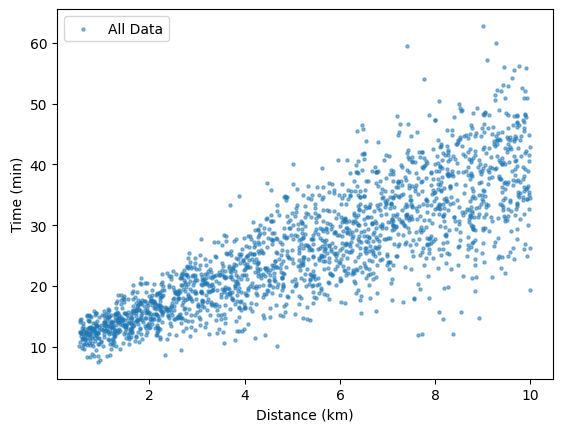

The model learned: 
9.74563273711031 [3.07267148]
k and q_hat are: 
451 9.401851102757675


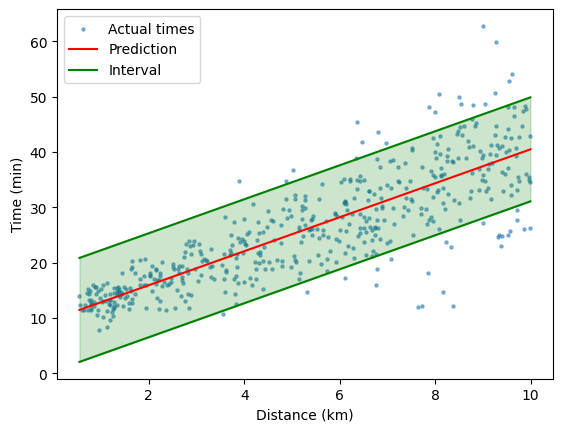

We have a total marginal coverage of: 
0.912
For distances below 3km we have a coverage of: 
1.0
For distances above 9km we have a coverage of: 
0.7377049180327869


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
import math

# Step 1 create the Data

# Pizza delivery example 
# x is the distance between the customer and the store (0.5km to 10km)
# Usual time (signal) is 10 + 3*x, so 10min to prepare the pizza and 3min per km.
# Noise: Normally distributed around 0, with standard deviation 1 + 0.8*x min. 
# Futher away means more traffic, red lights etc.

n = 2000    # Amount of deliverys
lowNum = 0.5  # Lowest possible km
highNum = 10    # Highest possible km

np.random.seed(42)  # Fixed Seed so we get the same random numbers every time
x = np.random.uniform(lowNum, highNum, n)   # Creates the 2000 random x values uniformly distributed
sd = 1 + 0.8 * x  # We create a standard deviation that varies with each point and gets bigger

noise = np.random.normal(0, sd, n)

y = (10 + 3*x) + noise

plt.scatter(x, y, s=5, alpha=0.5, label="All Data")
plt.xlabel("Distance (km)")
plt.ylabel("Time (min)")
plt.legend()
plt.show()

# Step 2, split data and train the model

# Now we split the data into train, calibration and test data
x_train, x_rest, y_train, y_rest = train_test_split(x, y, test_size=0.5, random_state=42)
x_cal, x_test, y_cal, y_test = train_test_split(x_rest, y_rest, test_size=0.5, random_state=42)

X_train = x_train.reshape(-1, 1)  # Reshape it to a table. -1 means as many rows as needed. 

model = LinearRegression()      # 1. create the model
model.fit(X_train, y_train)     # 2. train it on data
print("The model learned: ")
print(model.intercept_, model.coef_) # Print what it learned, true should be 10 and 3

# Step 3 calibrate

alpha = 0.1                     # Define our alpha for q_hat

X_cal = x_cal.reshape(-1, 1)    # Reshape the calibaration Data
predictions_cal = model.predict(X_cal)  # Predict

scores = np.abs(y_cal - predictions_cal)    # Takes the absolute value so direction doesnt matter

k = math.ceil((len(x_cal) + 1) * (1 - alpha))       # The formular
q_hat = np.sort(scores)[k - 1]
print("k and q_hat are: ")
print(k, q_hat)

# Step 4 Predict the test

X_test = x_test.reshape(-1,1)
predictions_test = model.predict(X_test)

lower_edge = predictions_test - q_hat
upper_edge = predictions_test + q_hat

order = np.argsort(x_test)  # So the line plot doesnt zick zack back and fourth we tell how to sort
plt.scatter(x_test, y_test, s=5, alpha=0.5, label="Actual times")
plt.plot(x_test[order], predictions_test[order], color="red", label="Prediction")
plt.plot(x_test[order], lower_edge[order], color="green", label="Interval")
plt.plot(x_test[order], upper_edge[order], color="green")
plt.fill_between(x_test[order], lower_edge[order], upper_edge[order], color="green", alpha=0.2)
plt.xlabel("Distance (km)")
plt.ylabel("Time (min)")
plt.legend()
plt.show()

# Step 5 Evaluate 

covered = (y_test >= lower_edge) & (y_test <= upper_edge)
print("We have a total marginal coverage of: ")
print(covered.mean())
near = x_test < 3
far = x_test > 9
print("For distances below 3km we have a coverage of: ")
print(covered[near].mean())
print("For distances above 9km we have a coverage of: ")
print(covered[far].mean())
